# Descomposicion de serie de tiempo en componentes de Tendencia, estacional y residual

In [4]:
# ================================================================
# 1. IMPORTAR LIBRERÍAS
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error


# ================================================================
# 2. CARGAR ARCHIVO EXCEL DESDE LA COMPUTADORA
# ================================================================

# Leer archivo Excel
df = pd.read_excel("./wunderground_IDURAN46_20260418_20260927.xlsx")

print("\nDimensiones del dataset:", df.shape)

print("\nColumnas disponibles:")
print(df.columns.tolist())

print("\nPrimeras observaciones:")
display(df.head())


Dimensiones del dataset: (37713, 37)

Columnas disponibles:
['stationID', 'tz', 'obsTimeUtc', 'obsTimeLocal', 'epoch', 'lat', 'lon', 'solarRadiationHigh', 'uvHigh', 'winddirAvg', 'humidityHigh', 'humidityLow', 'humidityAvg', 'qcStatus', 'tempHigh', 'tempLow', 'tempAvg', 'windspeedHigh', 'windspeedLow', 'windspeedAvg', 'windgustHigh', 'windgustLow', 'windgustAvg', 'dewptHigh', 'dewptLow', 'dewptAvg', 'windchillHigh', 'windchillLow', 'windchillAvg', 'heatindexHigh', 'heatindexLow', 'heatindexAvg', 'pressureMax', 'pressureMin', 'pressureTrend', 'precipRate', 'precipTotal']

Primeras observaciones:


,stationID,tz,obsTimeUtc,obsTimeLocal,epoch,lat,lon,solarRadiationHigh,uvHigh,winddirAvg,...,windchillLow,windchillAvg,heatindexHigh,heatindexLow,heatindexAvg,pressureMax,pressureMin,pressureTrend,precipRate,precipTotal
0,IDURAN46,America/Monterrey,2026-04-18T05:04:52Z,2026-04-18 00:04:52,1776488692,24.035684,-104.648617,0.0,0.0,235.0,...,21.8,21.9,20.9,20.7,20.8,1011.51,1011.18,-4.25,0.0,0.25
1,IDURAN46,America/Monterrey,2026-04-18T05:09:52Z,2026-04-18 00:09:52,1776488992,24.035684,-104.648617,0.0,0.0,218.0,...,21.7,21.8,20.8,20.6,20.7,1011.18,1011.18,0.00,0.0,0.25
2,IDURAN46,America/Monterrey,2026-04-18T05:14:52Z,2026-04-18 00:14:52,1776489292,24.035684,-104.648617,0.0,0.0,208.0,...,21.5,21.6,20.6,20.4,20.5,1011.18,1011.18,0.00,0.0,0.25
3,IDURAN46,America/Monterrey,2026-04-18T05:19:52Z,2026-04-18 00:19:52,1776489592,24.035684,-104.648617,0.0,0.0,214.0,...,21.5,21.6,20.7,20.4,20.4,1011.51,1011.18,4.25,0.0,0.25
4,IDURAN46,America/Monterrey,2026-04-18T05:24:52Z,2026-04-18 00:24:52,1776489892,24.035684,-104.648617,0.0,0.0,261.0,...,21.8,22.0,21.1,20.7,20.9,1011.51,1011.51,0.00,0.0,0.25


In [5]:
# ================================================================
# 3. PREPARAR TEMPERATURA Y HUMEDAD RELATIVA
# ================================================================

df["obsTimeLocal"] = pd.to_datetime(df["obsTimeLocal"])

datos = df[
    ["obsTimeLocal", "tempAvg", "humidityAvg"]
].copy()

datos = datos.sort_values("obsTimeLocal")
datos = datos.dropna()
datos = datos.set_index("obsTimeLocal")

print("Número de observaciones:", len(datos))

display(datos.head())

Número de observaciones: 37441


,tempAvg,humidityAvg
obsTimeLocal,,
2026-04-18 00:04:52,21.9,25.2
2026-04-18 00:09:52,21.8,25.8
2026-04-18 00:14:52,21.6,26.0
2026-04-18 00:19:52,21.6,25.0
2026-04-18 00:24:52,22.0,24.7



Dimensiones: (37713, 37)

Columnas:
['stationID', 'tz', 'obsTimeUtc', 'obsTimeLocal', 'epoch', 'lat', 'lon', 'solarRadiationHigh', 'uvHigh', 'winddirAvg', 'humidityHigh', 'humidityLow', 'humidityAvg', 'qcStatus', 'tempHigh', 'tempLow', 'tempAvg', 'windspeedHigh', 'windspeedLow', 'windspeedAvg', 'windgustHigh', 'windgustLow', 'windgustAvg', 'dewptHigh', 'dewptLow', 'dewptAvg', 'windchillHigh', 'windchillLow', 'windchillAvg', 'heatindexHigh', 'heatindexLow', 'heatindexAvg', 'pressureMax', 'pressureMin', 'pressureTrend', 'precipRate', 'precipTotal']

Número de observaciones: 37441

Periodo de observación:
2026-04-18 00:04:52 a 2026-09-27 10:45:28


,tempAvg,humidityAvg
obsTimeLocal,,
2026-04-18 00:04:52,21.9,25.2
2026-04-18 00:09:52,21.8,25.8
2026-04-18 00:14:52,21.6,26.0
2026-04-18 00:19:52,21.6,25.0
2026-04-18 00:24:52,22.0,24.7



INTERVALO DE MUESTREO
Intervalo mediano: 5.00 minutos
Muestras aproximadas por hora: 12.00
Muestras aproximadas por día: 288.00

Periodo estacional diario candidato: m = 288


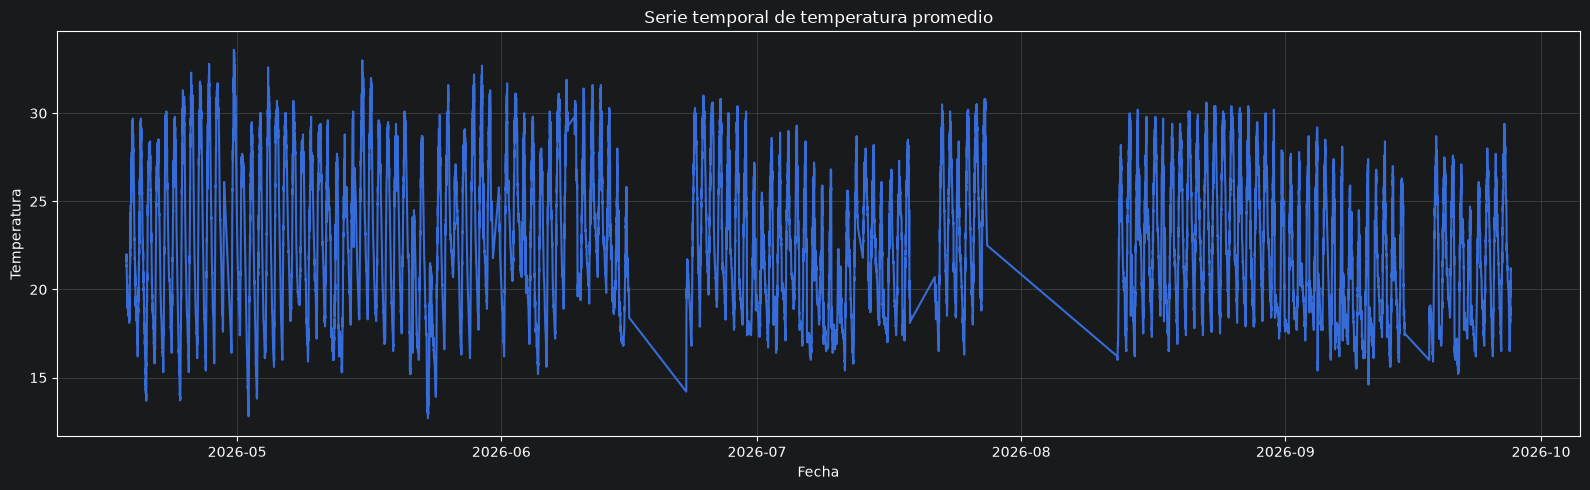

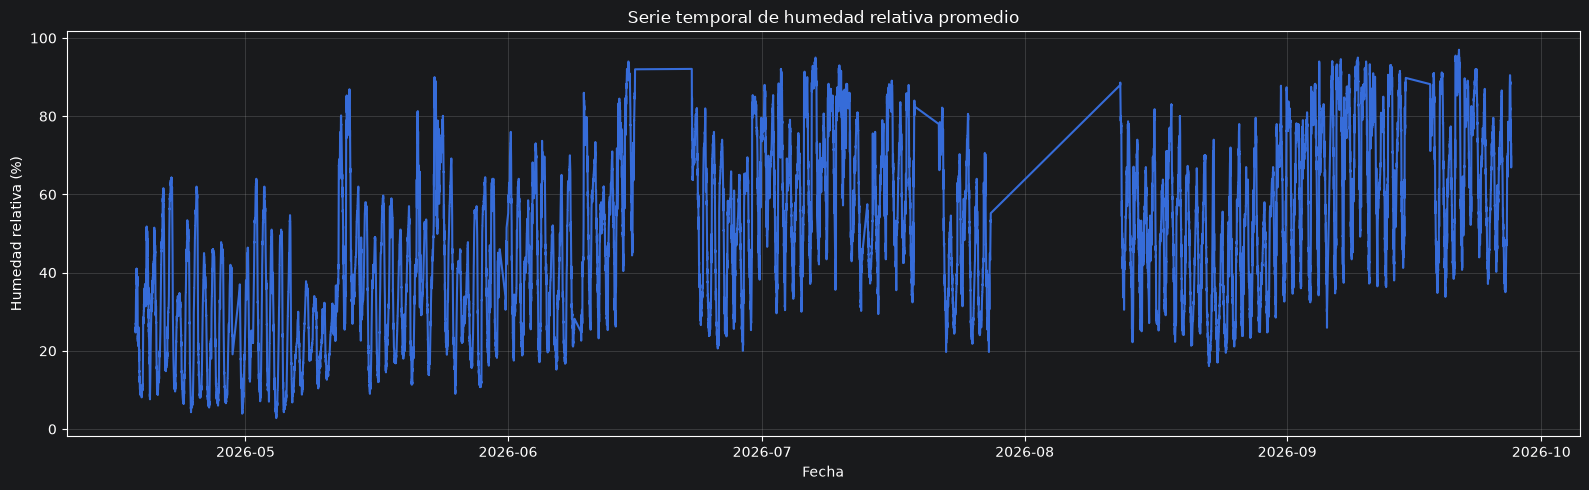

<Figure size 1600x600 with 0 Axes>

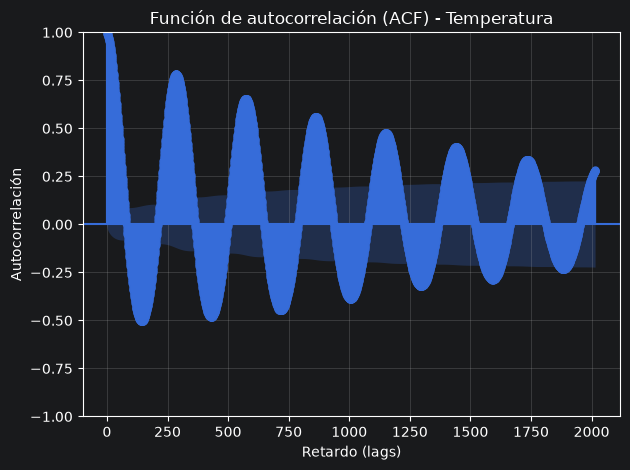

<Figure size 1600x600 with 0 Axes>

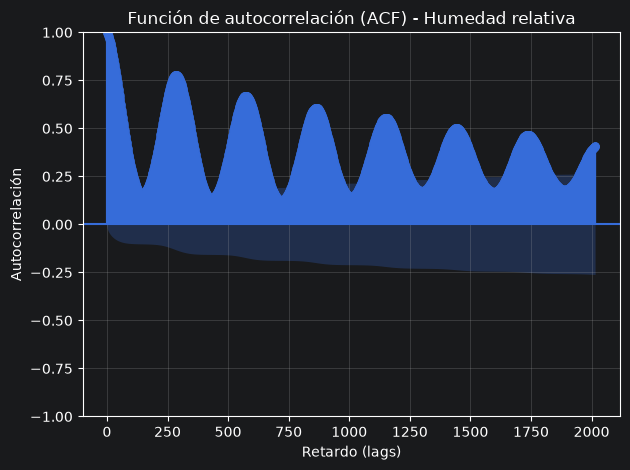


AUTOCORRELACIÓN EN CICLOS DIARIOS

Variable: tempAvg
1 día(s) (lag=288): 0.7857
2 día(s) (lag=576): 0.6616
3 día(s) (lag=864): 0.5707
4 día(s) (lag=1152): 0.4877
5 día(s) (lag=1440): 0.4176
6 día(s) (lag=1728): 0.3462
7 día(s) (lag=2016): 0.2979

Variable: humidityAvg
1 día(s) (lag=288): 0.7861
2 día(s) (lag=576): 0.6802
3 día(s) (lag=864): 0.6228
4 día(s) (lag=1152): 0.5733
5 día(s) (lag=1440): 0.5250
6 día(s) (lag=1728): 0.4915
7 día(s) (lag=2016): 0.4400

PERIODOS DOMINANTES: Temperatura
Periodo =   23.459 horas | Potencia = 8.2004e+03
Periodo =   24.376 horas | Potencia = 7.1414e+03
Periodo =   24.763 horas | Potencia = 5.0976e+03
Periodo =   24.001 horas | Potencia = 2.1693e+03
Periodo =   22.447 horas | Potencia = 1.2247e+03
Periodo =   25.574 horas | Potencia = 8.5826e+02
Periodo =   21.518 horas | Potencia = 6.5917e+02
Periodo =   12.047 horas | Potencia = 5.9421e+02
Periodo =  111.432 horas | Potencia = 4.0553e+02
Periodo =   21.972 horas | Potencia = 3.4777e+02


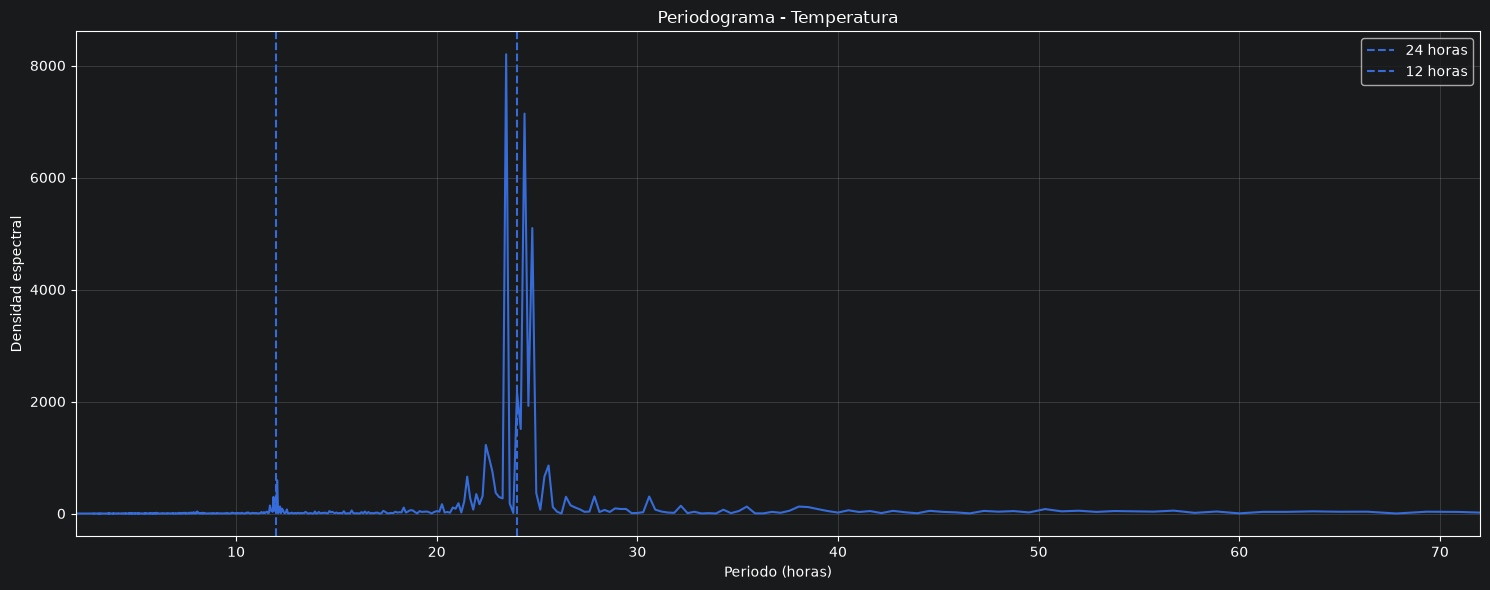


PERIODOS DOMINANTES: Humedad relativa
Periodo =   23.459 horas | Potencia = 1.2552e+05
Periodo =   24.376 horas | Potencia = 1.1178e+05
Periodo =   24.763 horas | Potencia = 7.7709e+04
Periodo =   25.574 horas | Potencia = 1.8333e+04
Periodo =  120.003 horas | Potencia = 1.5166e+04
Periodo =   21.518 horas | Potencia = 1.4488e+04
Periodo =   24.001 horas | Potencia = 1.3484e+04
Periodo =   22.447 horas | Potencia = 1.3233e+04
Periodo =   12.047 horas | Potencia = 8.9587e+03
Periodo =   22.942 horas | Potencia = 8.9550e+03


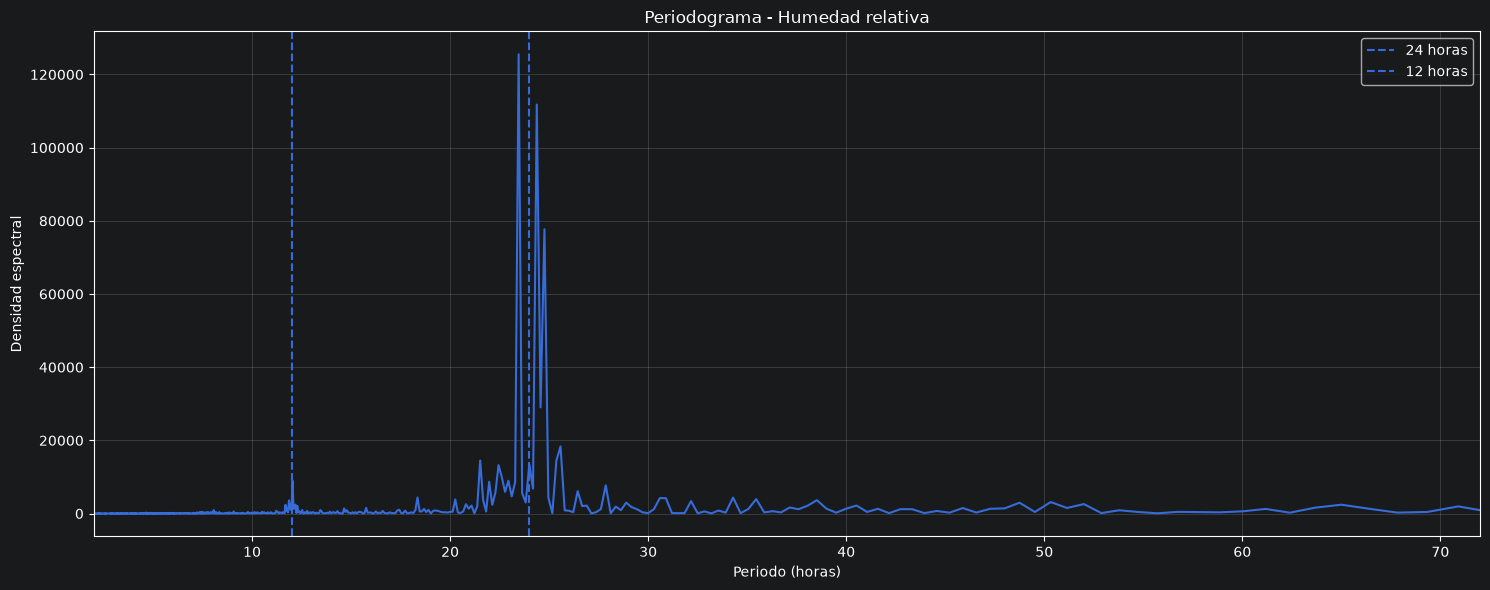

In [6]:
# ================================================================
# ANÁLISIS DE PERIODICIDAD
# Temperatura y Humedad Relativa
# ================================================================

# ------------------------------------------------
# 1. LIBRERÍAS
# ------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf
from scipy.signal import periodogram, find_peaks


# ================================================================
# 2. CARGAR ARCHIVO EXCEL
# ================================================================

df = pd.read_excel("./wunderground_IDURAN46_20260418_20260927.xlsx")

print("\nDimensiones:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())


# ================================================================
# 3. PREPARAR DATOS
# ================================================================

df["obsTimeLocal"] = pd.to_datetime(
    df["obsTimeLocal"],
    errors="coerce"
)

datos = df[
    ["obsTimeLocal", "tempAvg", "humidityAvg"]
].copy()

datos = datos.dropna()

datos = datos.sort_values("obsTimeLocal")

# Eliminar fechas duplicadas, si existen
datos = datos.drop_duplicates(
    subset="obsTimeLocal"
)

datos = datos.set_index("obsTimeLocal")


print("\nNúmero de observaciones:", len(datos))

print("\nPeriodo de observación:")
print(datos.index.min(), "a", datos.index.max())

display(datos.head())


# ================================================================
# 4. DETERMINAR INTERVALO DE MUESTREO
# ================================================================

diferencias = datos.index.to_series().diff().dropna()

delta_mediana = diferencias.median()

delta_minutos = (
    delta_mediana.total_seconds() / 60
)

print("\n==========================================")
print("INTERVALO DE MUESTREO")
print("==========================================")

print(
    f"Intervalo mediano: "
    f"{delta_minutos:.2f} minutos"
)

muestras_hora = 60 / delta_minutos
muestras_dia = 24 * muestras_hora

print(
    f"Muestras aproximadas por hora: "
    f"{muestras_hora:.2f}"
)

print(
    f"Muestras aproximadas por día: "
    f"{muestras_dia:.2f}"
)

m_diario = int(round(muestras_dia))

print(
    f"\nPeriodo estacional diario candidato: "
    f"m = {m_diario}"
)


# ================================================================
# 5. VISUALIZAR SERIES
# ================================================================

plt.figure(figsize=(16,5))

plt.plot(
    datos.index,
    datos["tempAvg"]
)

plt.title(
    "Serie temporal de temperatura promedio"
)

plt.xlabel("Fecha")
plt.ylabel("Temperatura")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(16,5))

plt.plot(
    datos.index,
    datos["humidityAvg"]
)

plt.title(
    "Serie temporal de humedad relativa promedio"
)

plt.xlabel("Fecha")
plt.ylabel("Humedad relativa (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ================================================================
# 6. AUTOCORRELACIÓN (ACF)
# ================================================================
#
# Se analizan hasta 7 días.
# Si el intervalo es de 5 minutos:
#
# 1 día = 288 retardos
# 2 días = 576
# 3 días = 864
# ...
#
# ================================================================

max_lag = 7 * m_diario


# ------------------------------------------------
# ACF TEMPERATURA
# ------------------------------------------------

plt.figure(figsize=(16,6))

plot_acf(
    datos["tempAvg"],
    lags=max_lag,
    zero=False
)

plt.title(
    "Función de autocorrelación (ACF) - Temperatura"
)

plt.xlabel("Retardo (lags)")
plt.ylabel("Autocorrelación")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------
# ACF HUMEDAD
# ------------------------------------------------

plt.figure(figsize=(16,6))

plot_acf(
    datos["humidityAvg"],
    lags=max_lag,
    zero=False
)

plt.title(
    "Función de autocorrelación (ACF) - Humedad relativa"
)

plt.xlabel("Retardo (lags)")
plt.ylabel("Autocorrelación")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ================================================================
# 7. AUTOCORRELACIÓN EN RETARDOS DE 24 HORAS
# ================================================================

print("\n==========================================")
print("AUTOCORRELACIÓN EN CICLOS DIARIOS")
print("==========================================")

for variable in ["tempAvg", "humidityAvg"]:

    print("\nVariable:", variable)

    for dia in range(1, 8):

        lag = dia * m_diario

        correlacion = datos[variable].autocorr(
            lag=lag
        )

        print(
            f"{dia} día(s) "
            f"(lag={lag}): "
            f"{correlacion:.4f}"
        )


# ================================================================
# 8. PERIODOGRAMA
# ================================================================
#
# La frecuencia de muestreo se expresa en muestras/hora.
#
# El periodo obtenido estará expresado en horas.
# ================================================================

fs = muestras_hora


def analizar_periodograma(serie, nombre):

    # Eliminar media
    x = serie.values
    x = x - np.mean(x)

    # Calcular periodograma
    frecuencias, potencia = periodogram(
        x,
        fs=fs,
        detrend="linear"
    )

    # Eliminar frecuencia cero
    mascara = frecuencias > 0

    frecuencias = frecuencias[mascara]
    potencia = potencia[mascara]

    # Convertir frecuencia a periodo
    periodos_horas = 1 / frecuencias

    # ------------------------------------------------
    # Buscar periodos entre 2 horas y 7 días
    # ------------------------------------------------

    mascara_periodo = (
        (periodos_horas >= 2) &
        (periodos_horas <= 168)
    )

    p = periodos_horas[mascara_periodo]
    power = potencia[mascara_periodo]

    # ------------------------------------------------
    # Encontrar picos
    # ------------------------------------------------

    peaks, _ = find_peaks(power)

    if len(peaks) > 0:

        indices = peaks[
            np.argsort(power[peaks])[-10:]
        ]

        indices = indices[
            np.argsort(power[indices])[::-1]
        ]

        print("\n==========================================")
        print("PERIODOS DOMINANTES:", nombre)
        print("==========================================")

        for i in indices:

            print(
                f"Periodo = {p[i]:8.3f} horas | "
                f"Potencia = {power[i]:.4e}"
            )

    # ------------------------------------------------
    # Gráfica
    # ------------------------------------------------

    plt.figure(figsize=(15,6))

    plt.plot(
        p,
        power
    )

    plt.axvline(
        24,
        linestyle="--",
        label="24 horas"
    )

    plt.axvline(
        12,
        linestyle="--",
        label="12 horas"
    )

    plt.xlim(2, 72)

    plt.xlabel("Periodo (horas)")
    plt.ylabel("Densidad espectral")

    plt.title(
        f"Periodograma - {nombre}"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# ================================================================
# 9. PERIODOGRAMA TEMPERATURA
# ================================================================

analizar_periodograma(
    datos["tempAvg"],
    "Temperatura"
)


# ================================================================
# 10. PERIODOGRAMA HUMEDAD RELATIVA
# ================================================================

analizar_periodograma(
    datos["humidityAvg"],
    "Humedad relativa"
)

Periodo estacional utilizado:
m = 288 observaciones

DIVISIÓN DEL DATASET
Total de observaciones : 37441
Entrenamiento          : 29952
Prueba                 : 7489

Periodo entrenamiento:
2026-04-18 00:04:52 -> 2026-08-29 01:09:53

Periodo prueba:
2026-08-29 01:14:53 -> 2026-09-27 10:45:28

TEMPERATURA


,Modelo,MAE,RMSE,MAPE (%),R2
0,Average,3.4769,3.9369,17.9814,-0.3206
1,Naive,3.6352,4.1315,18.9657,-0.4544
2,Seasonal_Naive,5.2141,6.3018,26.8428,-2.3837
3,Drift,3.7096,4.2269,19.4205,-0.5223



HUMEDAD RELATIVA


,Modelo,MAE,RMSE,MAPE (%),R2
0,Average,23.5594,27.7971,31.9467,-1.5456
1,Naive,25.8802,30.3172,34.8640,-2.0282
2,Seasonal_Naive,28.3663,34.0283,40.8723,-2.8149
3,Drift,24.2318,28.5729,32.6859,-1.6897



COMPARACIÓN GENERAL


,Variable,Modelo,MAE,RMSE,MAPE (%),R2
0,Temperatura,Average,3.4769,3.9369,17.9814,-0.3206
1,Temperatura,Naive,3.6352,4.1315,18.9657,-0.4544
2,Temperatura,Seasonal_Naive,5.2141,6.3018,26.8428,-2.3837
3,Temperatura,Drift,3.7096,4.2269,19.4205,-0.5223
4,Humedad relativa,Average,23.5594,27.7971,31.9467,-1.5456
5,Humedad relativa,Naive,25.8802,30.3172,34.8640,-2.0282
6,Humedad relativa,Seasonal_Naive,28.3663,34.0283,40.8723,-2.8149
7,Humedad relativa,Drift,24.2318,28.5729,32.6859,-1.6897



MEJOR MODELO SEGÚN RMSE

Temperatura: Average
RMSE = 3.9369
MAE  = 3.4769
MAPE = 17.9814 %
R²   = -0.3206

Humedad relativa: Average
RMSE = 27.7971
MAE  = 23.5594
MAPE = 31.9467 %
R²   = -1.5456


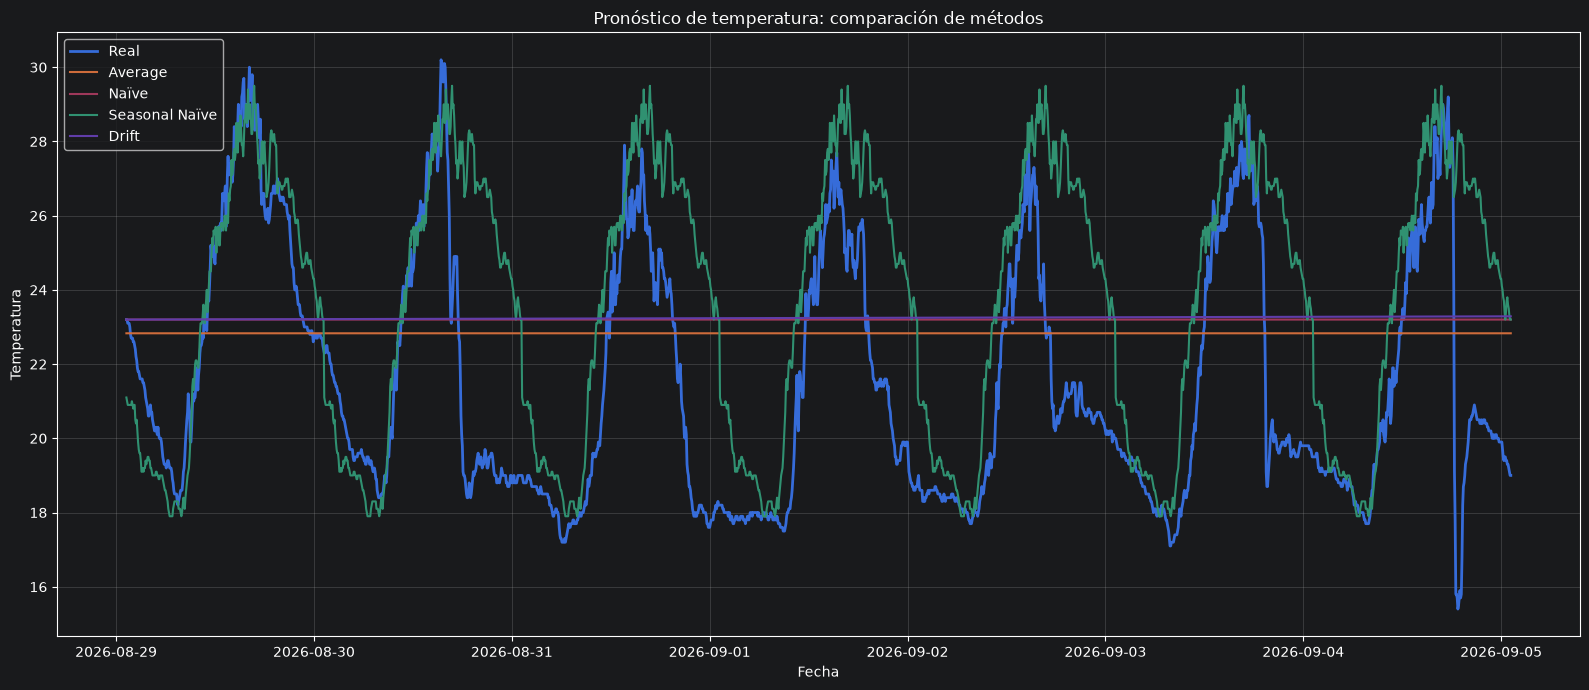

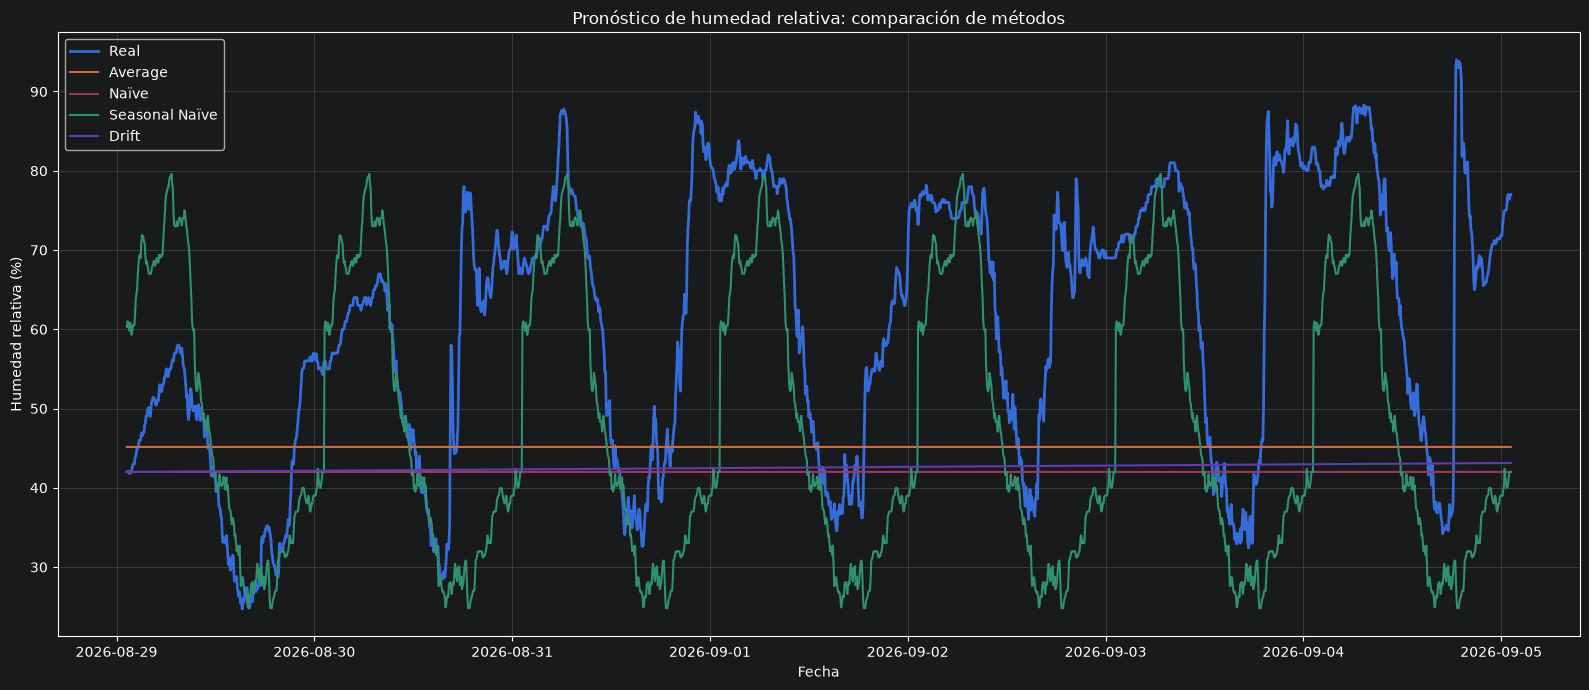

In [8]:
# ================================================================
# COMPARACIÓN DE MÉTODOS BÁSICOS DE PRONÓSTICO
#
# 1. Average
# 2. Naïve
# 3. Seasonal Naïve
# 4. Drift
#
# Variables:
#   tempAvg      -> Temperatura
#   humidityAvg  -> Humedad relativa
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ================================================================
# 1. PERIODO ESTACIONAL
# ================================================================
#
# Usamos el periodo diario calculado anteriormente.
# Si el intervalo es de 5 minutos:
#
#     m = 24 * 60 / 5 = 288
#
# m_diario ya fue calculado en el script anterior.
# ================================================================

m = m_diario

print("Periodo estacional utilizado:")
print(f"m = {m} observaciones")


# ================================================================
# 2. DIVISIÓN CRONOLÓGICA 80/20
# ================================================================

n = len(datos)

n_train = int(0.80 * n)

train = datos.iloc[:n_train].copy()
test  = datos.iloc[n_train:].copy()

print("\n==============================================")
print("DIVISIÓN DEL DATASET")
print("==============================================")

print(f"Total de observaciones : {n}")
print(f"Entrenamiento          : {len(train)}")
print(f"Prueba                 : {len(test)}")

print("\nPeriodo entrenamiento:")
print(train.index.min(), "->", train.index.max())

print("\nPeriodo prueba:")
print(test.index.min(), "->", test.index.max())


# ================================================================
# 3. MÉTODO AVERAGE
# ================================================================

def average_forecast(y_train, h):

    media = y_train.mean()

    return np.repeat(media, h)


# ================================================================
# 4. MÉTODO NAÏVE
# ================================================================

def naive_forecast(y_train, h):

    ultimo = y_train.iloc[-1]

    return np.repeat(ultimo, h)


# ================================================================
# 5. MÉTODO SEASONAL NAÏVE
# ================================================================

def seasonal_naive_forecast(y_train, h, m):

    if len(y_train) < m:
        raise ValueError(
            "No existen suficientes observaciones "
            "para completar un periodo estacional."
        )

    ultima_temporada = y_train.iloc[-m:].to_numpy()

    pronostico = np.resize(
        ultima_temporada,
        h
    )

    return pronostico


# ================================================================
# 6. MÉTODO DRIFT
# ================================================================

def drift_forecast(y_train, h):

    y1 = y_train.iloc[0]
    yT = y_train.iloc[-1]

    T = len(y_train)

    pendiente = (yT - y1) / (T - 1)

    pasos = np.arange(1, h + 1)

    pronostico = (
        yT +
        pasos * pendiente
    )

    return pronostico


# ================================================================
# 7. MÉTRICAS
# ================================================================

def metricas(real, pred):

    real = np.asarray(real)
    pred = np.asarray(pred)

    mae = mean_absolute_error(
        real,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            real,
            pred
        )
    )

    r2 = r2_score(
        real,
        pred
    )

    # -----------------------------------------------
    # MAPE
    # -----------------------------------------------

    mascara = real != 0

    if np.any(mascara):

        mape = (
            np.mean(
                np.abs(
                    (real[mascara] - pred[mascara])
                    / real[mascara]
                )
            )
            * 100
        )

    else:

        mape = np.nan

    return mae, rmse, mape, r2


# ================================================================
# 8. FUNCIÓN GENERAL DE EVALUACIÓN
# ================================================================

def evaluar_modelos(
    train,
    test,
    variable,
    m
):

    y_train = train[variable]
    y_test = test[variable]

    h = len(y_test)

    # -----------------------------------------------
    # Pronósticos
    # -----------------------------------------------

    pred_average = average_forecast(
        y_train,
        h
    )

    pred_naive = naive_forecast(
        y_train,
        h
    )

    pred_snaive = seasonal_naive_forecast(
        y_train,
        h,
        m
    )

    pred_drift = drift_forecast(
        y_train,
        h
    )

    # -----------------------------------------------
    # DataFrame de resultados
    # -----------------------------------------------

    predicciones = pd.DataFrame(
        {
            "Real": y_test.to_numpy(),

            "Average":
                pred_average,

            "Naive":
                pred_naive,

            "Seasonal_Naive":
                pred_snaive,

            "Drift":
                pred_drift
        },

        index=y_test.index
    )

    # -----------------------------------------------
    # Calcular métricas
    # -----------------------------------------------

    resultados = []

    modelos = [
        "Average",
        "Naive",
        "Seasonal_Naive",
        "Drift"
    ]

    for modelo in modelos:

        mae, rmse, mape, r2 = metricas(
            predicciones["Real"],
            predicciones[modelo]
        )

        resultados.append(
            {
                "Modelo": modelo,
                "MAE": mae,
                "RMSE": rmse,
                "MAPE (%)": mape,
                "R2": r2
            }
        )

    tabla = pd.DataFrame(resultados)

    return predicciones, tabla


# ================================================================
# 9. EVALUACIÓN DE TEMPERATURA
# ================================================================

pred_temp, met_temp = evaluar_modelos(
    train,
    test,
    "tempAvg",
    m
)

met_temp["Variable"] = "Temperatura"


print("\n==============================================")
print("TEMPERATURA")
print("==============================================")

display(
    met_temp[
        [
            "Modelo",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "R2"
        ]
    ].round(4)
)


# ================================================================
# 10. EVALUACIÓN DE HUMEDAD RELATIVA
# ================================================================

pred_hum, met_hum = evaluar_modelos(
    train,
    test,
    "humidityAvg",
    m
)

met_hum["Variable"] = "Humedad relativa"


print("\n==============================================")
print("HUMEDAD RELATIVA")
print("==============================================")

display(
    met_hum[
        [
            "Modelo",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "R2"
        ]
    ].round(4)
)


# ================================================================
# 11. TABLA GENERAL
# ================================================================

comparacion = pd.concat(
    [
        met_temp,
        met_hum
    ],
    ignore_index=True
)

comparacion = comparacion[
    [
        "Variable",
        "Modelo",
        "MAE",
        "RMSE",
        "MAPE (%)",
        "R2"
    ]
]


print("\n==============================================")
print("COMPARACIÓN GENERAL")
print("==============================================")

display(
    comparacion.round(4)
)


# ================================================================
# 12. MEJOR MODELO SEGÚN RMSE
# ================================================================

print("\n==============================================")
print("MEJOR MODELO SEGÚN RMSE")
print("==============================================")

for variable in comparacion["Variable"].unique():

    aux = comparacion[
        comparacion["Variable"] == variable
    ]

    mejor = aux.loc[
        aux["RMSE"].idxmin()
    ]

    print(
        f"\n{variable}: "
        f"{mejor['Modelo']}"
    )

    print(
        f"RMSE = {mejor['RMSE']:.4f}"
    )

    print(
        f"MAE  = {mejor['MAE']:.4f}"
    )

    print(
        f"MAPE = {mejor['MAPE (%)']:.4f} %"
    )

    print(
        f"R²   = {mejor['R2']:.4f}"
    )


# ================================================================
# 13. GRÁFICA TEMPERATURA
# ================================================================
#
# Se muestran los primeros 7 días del conjunto de prueba.
# ================================================================

n_grafica = min(
    7 * m,
    len(pred_temp)
)

plt.figure(figsize=(16,7))

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Real"].iloc[:n_grafica],
    label="Real",
    linewidth=2
)

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Average"].iloc[:n_grafica],
    label="Average"
)

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Naive"].iloc[:n_grafica],
    label="Naïve"
)

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Seasonal_Naive"].iloc[:n_grafica],
    label="Seasonal Naïve"
)

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Drift"].iloc[:n_grafica],
    label="Drift"
)

plt.title(
    "Pronóstico de temperatura: comparación de métodos"
)

plt.xlabel("Fecha")
plt.ylabel("Temperatura")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ================================================================
# 14. GRÁFICA HUMEDAD RELATIVA
# ================================================================

n_grafica = min(
    7 * m,
    len(pred_hum)
)

plt.figure(figsize=(16,7))

plt.plot(
    pred_hum.index[:n_grafica],
    pred_hum["Real"].iloc[:n_grafica],
    label="Real",
    linewidth=2
)

plt.plot(
    pred_hum.index[:n_grafica],
    pred_hum["Average"].iloc[:n_grafica],
    label="Average"
)

plt.plot(
    pred_hum.index[:n_grafica],
    pred_hum["Naive"].iloc[:n_grafica],
    label="Naïve"
)

plt.plot(
    pred_hum.index[:n_grafica],
    pred_hum["Seasonal_Naive"].iloc[:n_grafica],
    label="Seasonal Naïve"
)

plt.plot(
    pred_hum.index[:n_grafica],
    pred_hum["Drift"].iloc[:n_grafica],
    label="Drift"
)

plt.title(
    "Pronóstico de humedad relativa: comparación de métodos"
)

plt.xlabel("Fecha")
plt.ylabel("Humedad relativa (%)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ================================================================
# ANÁLISIS DE RESIDUALES / ERRORES DE PRONÓSTICO
#
# e_t = y_t - y_hat_t
#
# Métodos:
#   1. Average
#   2. Naïve
#   3. Seasonal Naïve
#   4. Drift
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox


# ================================================================
# 1. FUNCIÓN PARA CALCULAR RESIDUALES
# ================================================================

def calcular_residuales(predicciones):

    residuales = pd.DataFrame(
        index=predicciones.index
    )

    modelos = [
        "Average",
        "Naive",
        "Seasonal_Naive",
        "Drift"
    ]

    for modelo in modelos:

        residuales[modelo] = (
            predicciones["Real"]
            - predicciones[modelo]
        )

    return residuales


# ================================================================
# 2. RESIDUALES DE TEMPERATURA
# ================================================================

res_temp = calcular_residuales(
    pred_temp
)

print("RESIDUALES - TEMPERATURA")

display(
    res_temp.head(10)
)


# ================================================================
# 3. RESIDUALES DE HUMEDAD RELATIVA
# ================================================================

res_hum = calcular_residuales(
    pred_hum
)

print("RESIDUALES - HUMEDAD RELATIVA")

display(
    res_hum.head(10)
)

RESIDUALES - TEMPERATURA


,Average,Naive,Seasonal_Naive,Drift
obsTimeLocal,,,,
2026-08-29 01:14:53,0.369641,0.0,2.1,-0.000043
2026-08-29 01:19:53,0.369641,0.0,2.2,-0.000087
2026-08-29 01:24:53,0.269641,-0.1,2.2,-0.100130
2026-08-29 01:29:53,0.269641,-0.1,2.2,-0.100174
2026-08-29 01:34:53,0.269641,-0.1,2.2,-0.100217
2026-08-29 01:39:53,0.169641,-0.2,2.1,-0.200260
2026-08-29 01:44:53,-0.030359,-0.4,1.9,-0.400304
2026-08-29 01:49:53,-0.130359,-0.5,1.8,-0.500347
2026-08-29 01:54:53,-0.130359,-0.5,1.7,-0.500391


RESIDUALES - HUMEDAD RELATIVA


,Average,Naive,Seasonal_Naive,Drift
obsTimeLocal,,,,
2026-08-29 01:14:53,-3.151573,0.0,-18.3,-0.000561
2026-08-29 01:19:53,-3.151573,0.0,-19.0,-0.001122
2026-08-29 01:24:53,-3.151573,0.0,-18.9,-0.001683
2026-08-29 01:29:53,-3.051573,0.1,-18.3,0.097756
2026-08-29 01:34:53,-3.351573,-0.2,-18.0,-0.202805
2026-08-29 01:39:53,-3.151573,0.0,-18.8,-0.003365
2026-08-29 01:44:53,-3.151573,0.0,-18.3,-0.003926
2026-08-29 01:49:53,-3.151573,0.0,-17.3,-0.004487
2026-08-29 01:54:53,-2.451573,0.7,-17.1,0.694952


In [ ]:
# ================================================================
# 4. ESTADÍSTICA DESCRIPTIVA DE LOS RESIDUALES
# ================================================================

def resumen_residuales(residuales):

    resumen = pd.DataFrame({

        "Media":
            residuales.mean(),

        "Desv. estándar":
            residuales.std(),

        "Mínimo":
            residuales.min(),

        "Máximo":
            residuales.max(),

        "Mediana":
            residuales.median(),

        "RMSE":
            np.sqrt(
                (residuales**2).mean()
            )

    })

    return resumen


# ------------------------------------------------
# Temperatura
# ------------------------------------------------

resumen_temp = resumen_residuales(
    res_temp
)

print("\n======================================")
print("RESUMEN RESIDUALES - TEMPERATURA")
print("======================================")

display(
    resumen_temp.round(4)
)


# ------------------------------------------------
# Humedad
# ------------------------------------------------

resumen_hum = resumen_residuales(
    res_hum
)

print("\n======================================")
print("RESUMEN RESIDUALES - HUMEDAD")
print("======================================")

display(
    resumen_hum.round(4)
)


RESUMEN RESIDUALES - TEMPERATURA


,Media,Desv. estándar,Mínimo,Máximo,Mediana,RMSE
Average,-1.9397,3.4261,-8.2304,7.3696,-2.8304,3.9369
Naive,-2.3093,3.4261,-8.6000,7.0000,-3.2000,4.1315
Seasonal_Naive,-2.8149,5.6386,-13.3000,11.2000,-2.5000,6.3018
Drift,-2.4719,3.4290,-8.7525,6.9801,-3.3733,4.2269



RESUMEN RESIDUALES - HUMEDAD


,Media,Desv. estándar,Mínimo,Máximo,Mediana,RMSE
Average,21.6598,17.4233,-20.4516,51.8484,23.8484,27.7971
Naive,24.8114,17.4233,-17.3000,55.0000,27.0000,30.3172
Seasonal_Naive,19.1729,28.1146,-43.7000,69.2000,18.0000,34.0283
Drift,22.7107,17.3400,-17.3948,51.7955,25.2780,28.5729


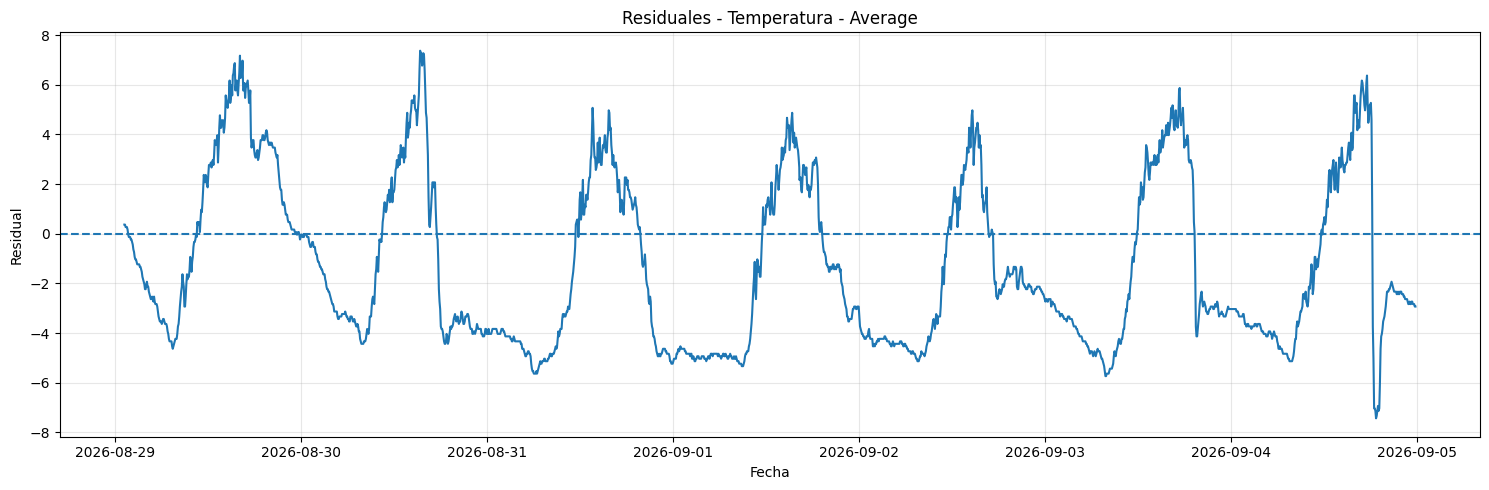

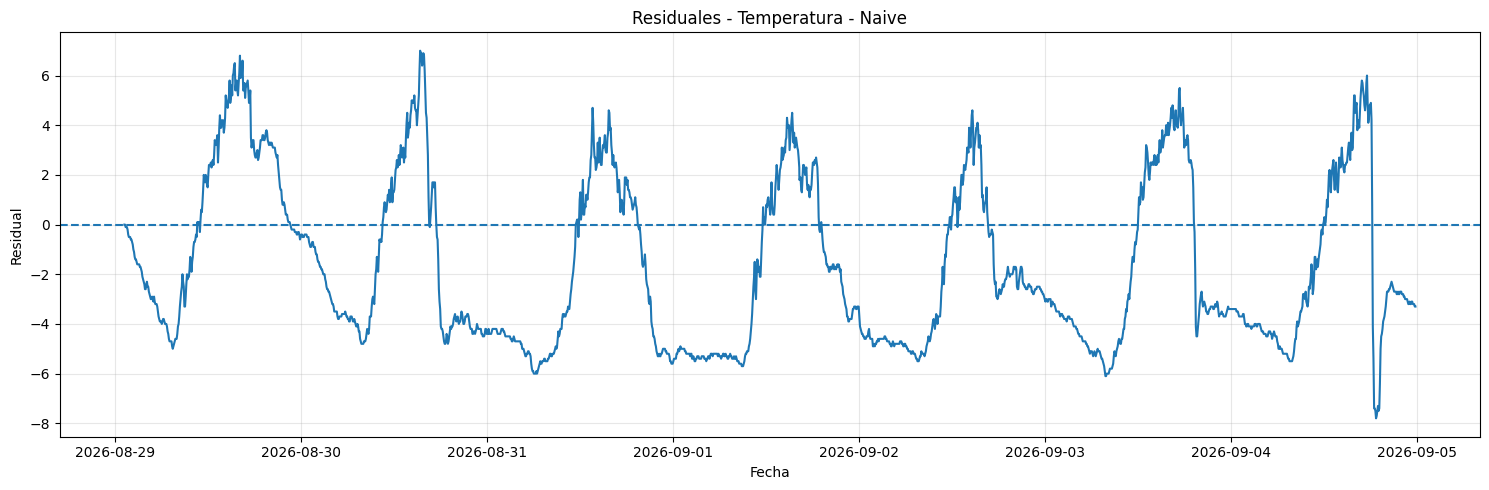

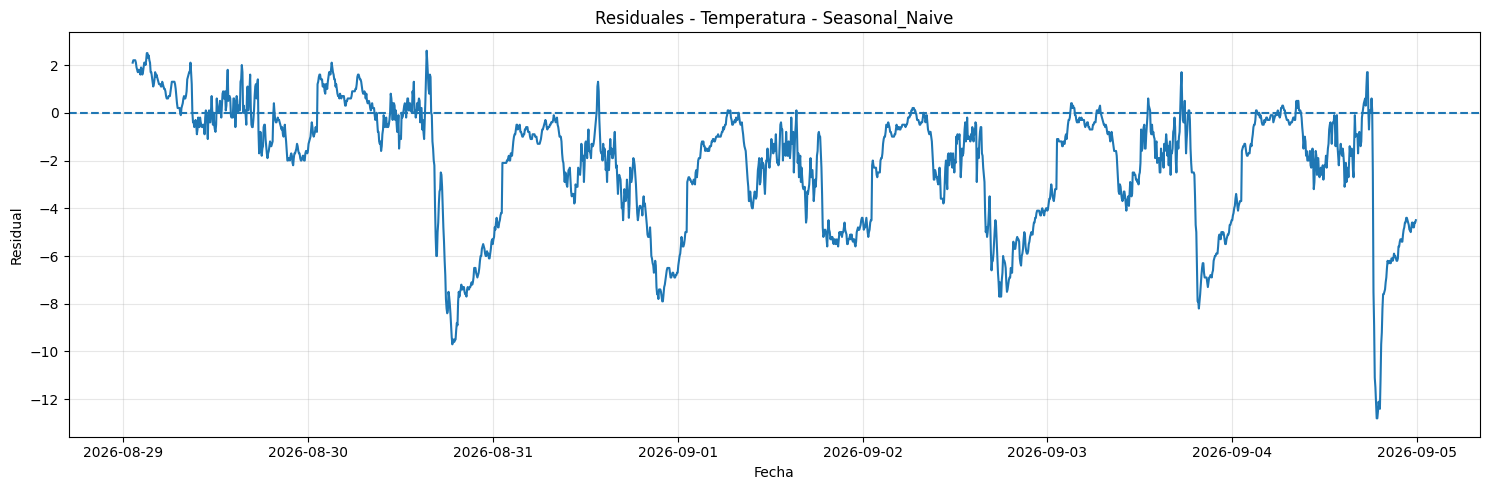

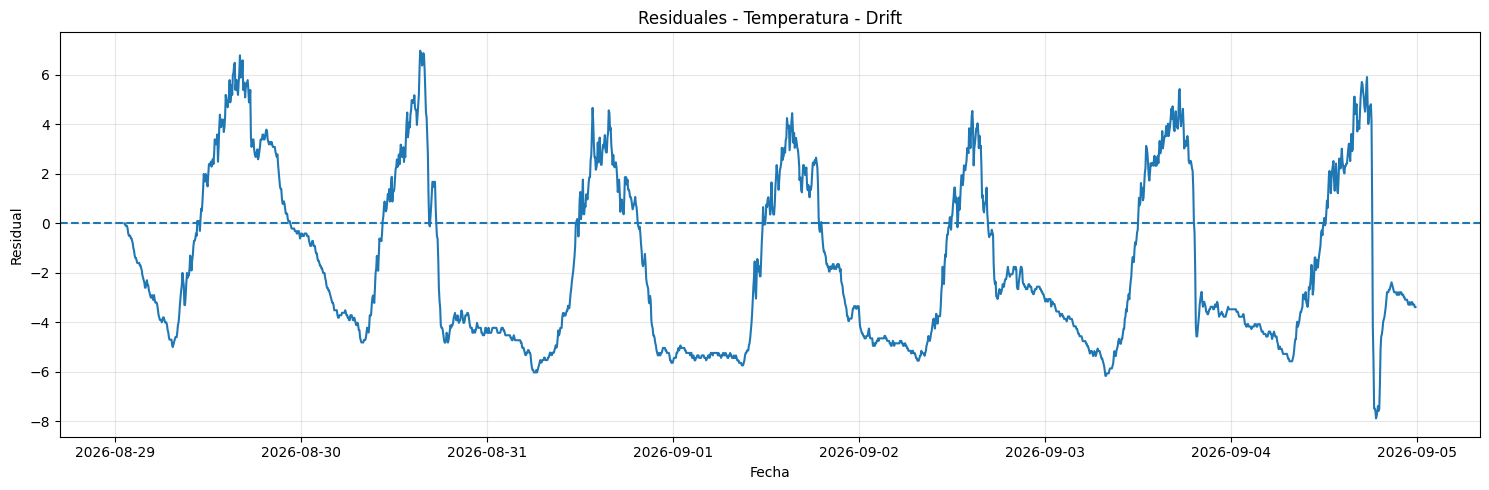

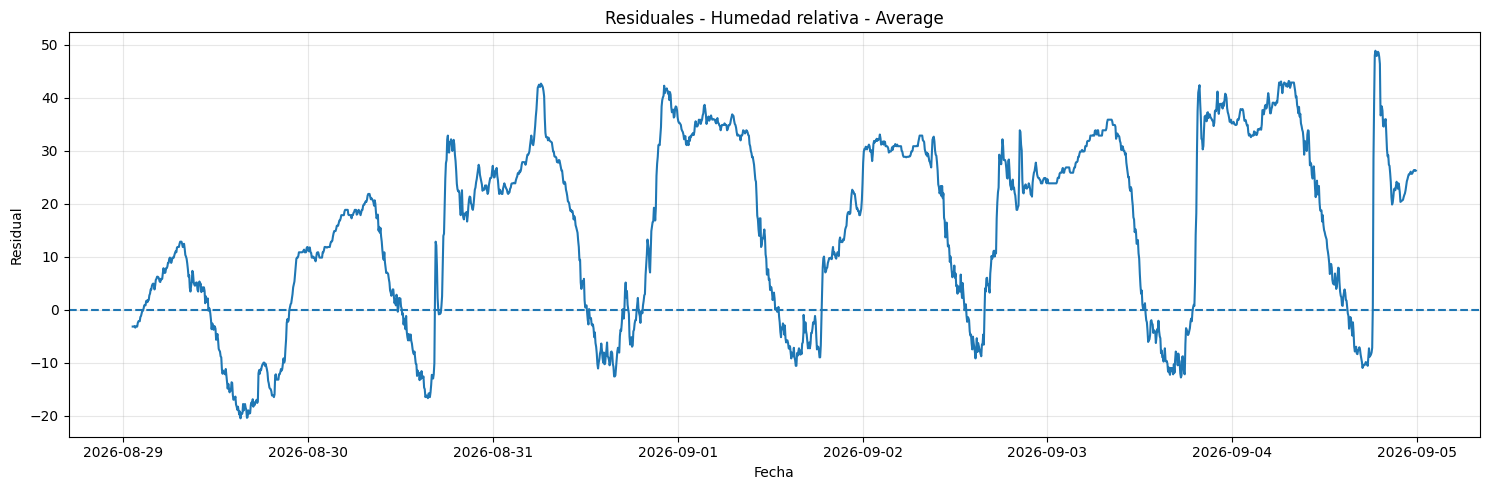

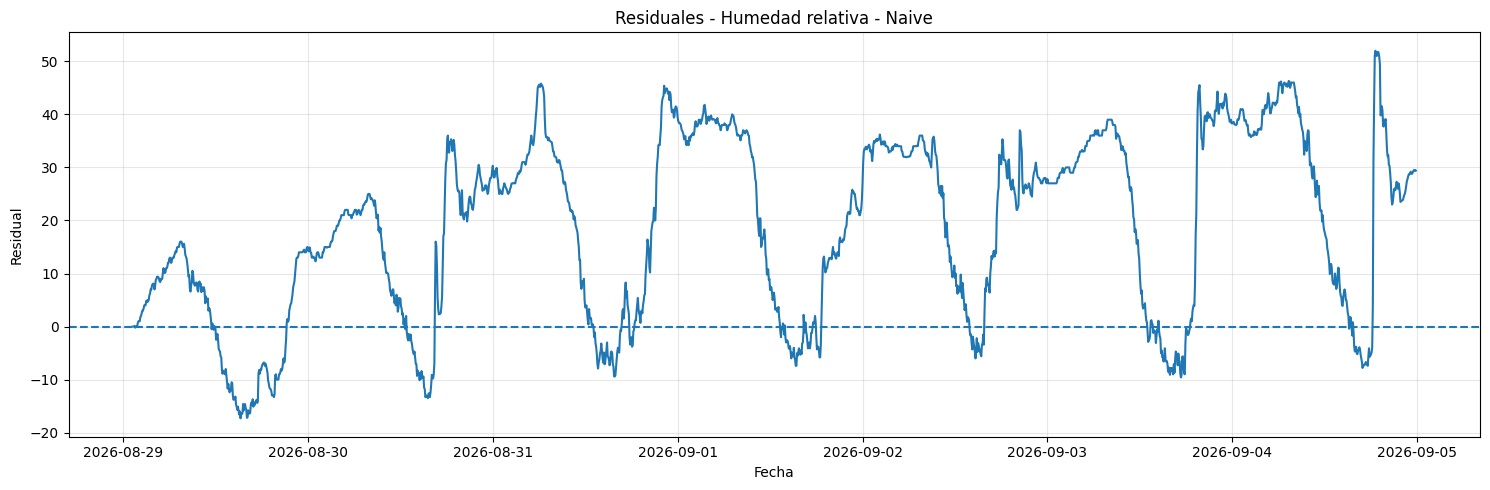

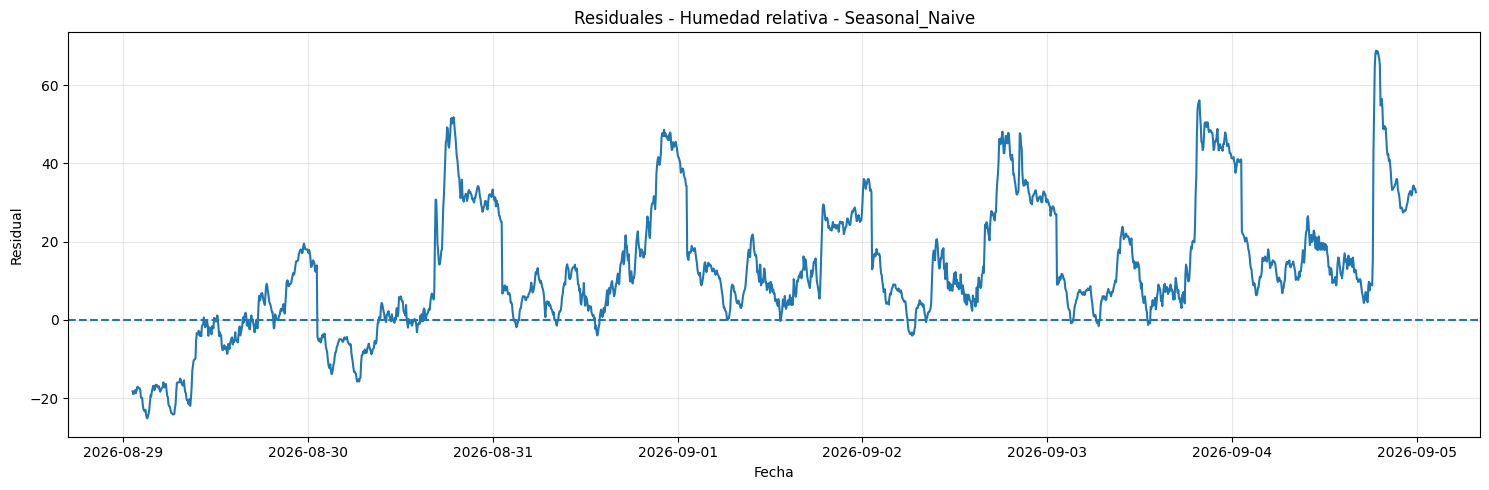

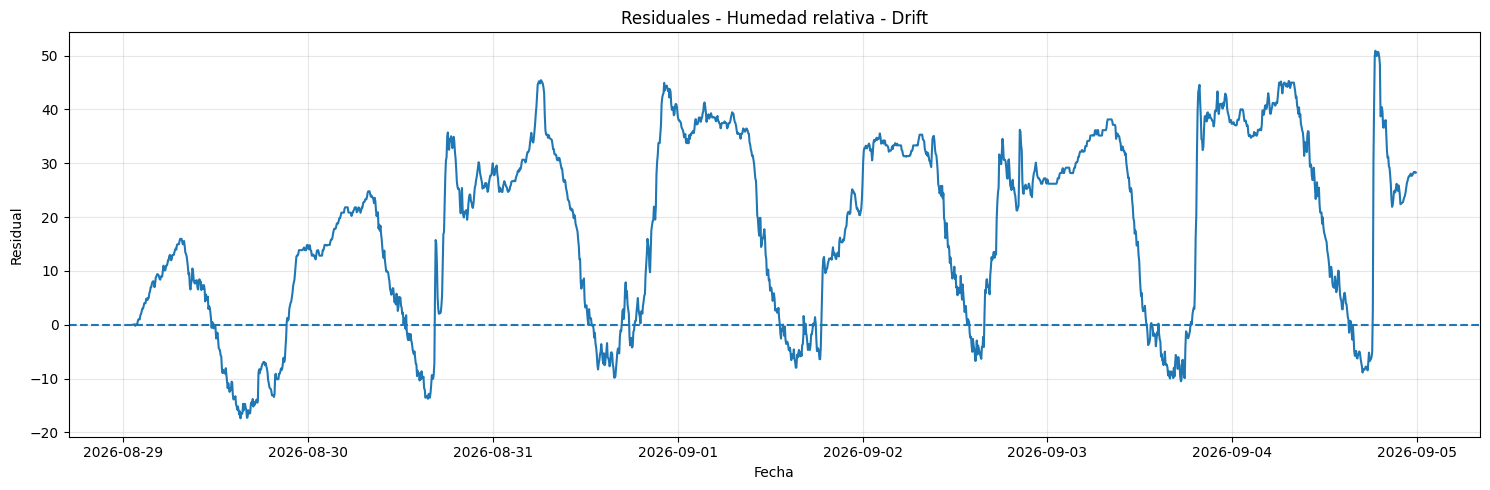

In [ ]:
# ================================================================
# 5. GRÁFICAS DE RESIDUALES
# ================================================================

def graficar_residuales(
    residuales,
    variable,
    n=2000
):

    modelos = residuales.columns

    n = min(
        n,
        len(residuales)
    )

    for modelo in modelos:

        plt.figure(
            figsize=(15, 5)
        )

        plt.plot(
            residuales.index[:n],
            residuales[modelo].iloc[:n]
        )

        plt.axhline(
            y=0,
            linestyle="--"
        )

        plt.title(
            f"Residuales - {variable} - {modelo}"
        )

        plt.xlabel("Fecha")
        plt.ylabel("Residual")

        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()


# Temperatura

graficar_residuales(
    res_temp,
    "Temperatura"
)


# Humedad relativa

graficar_residuales(
    res_hum,
    "Humedad relativa"
)

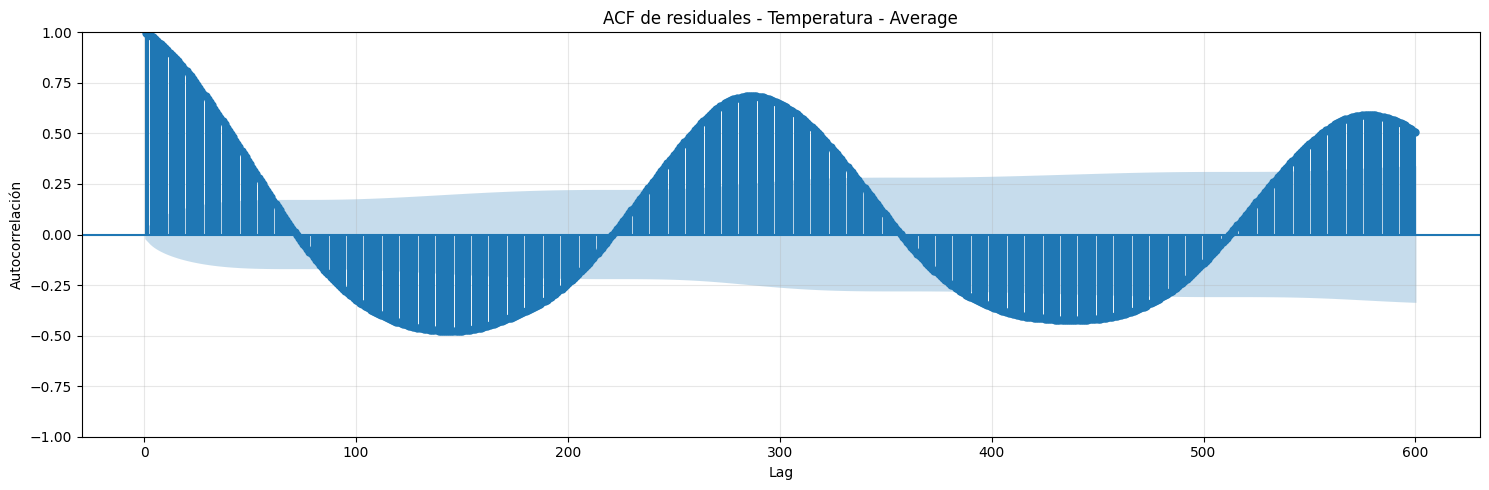

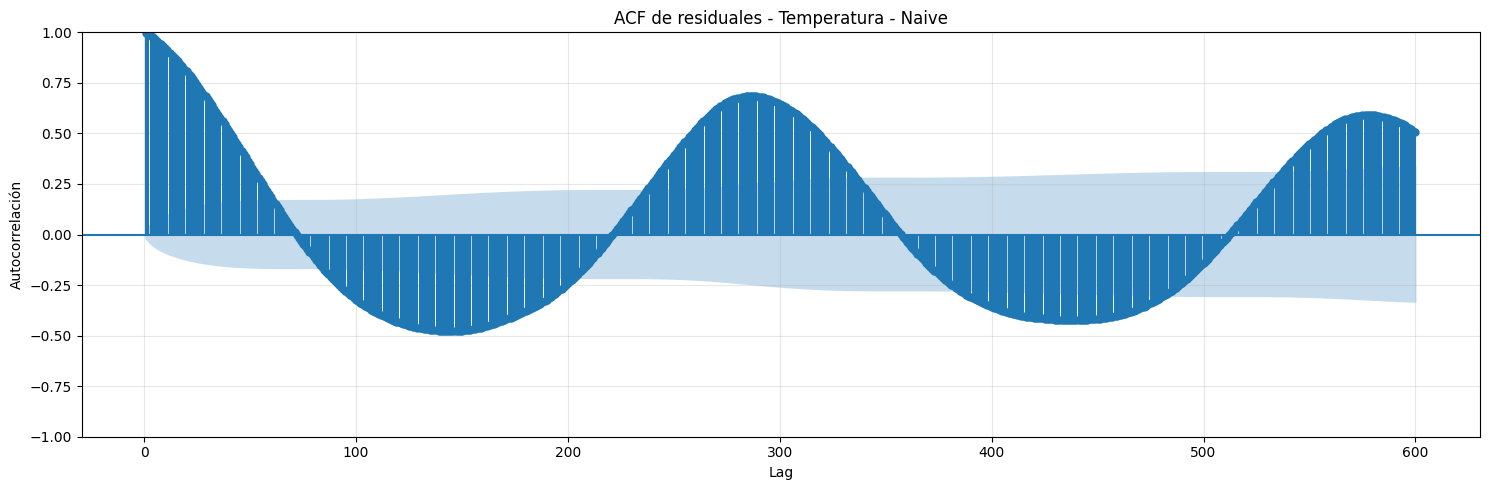

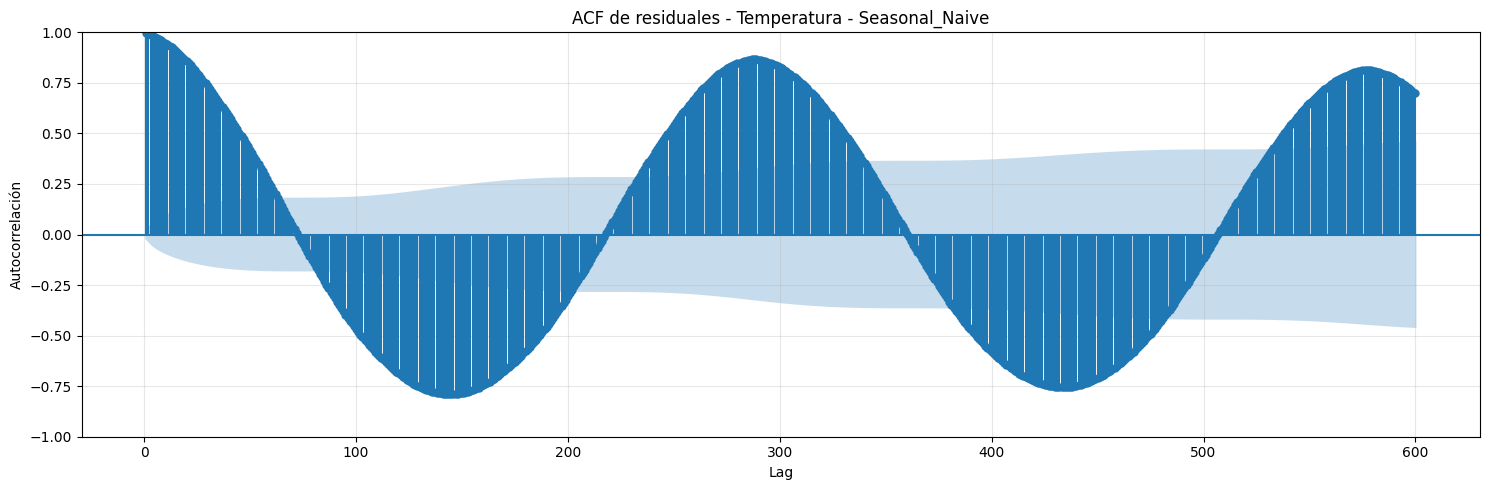

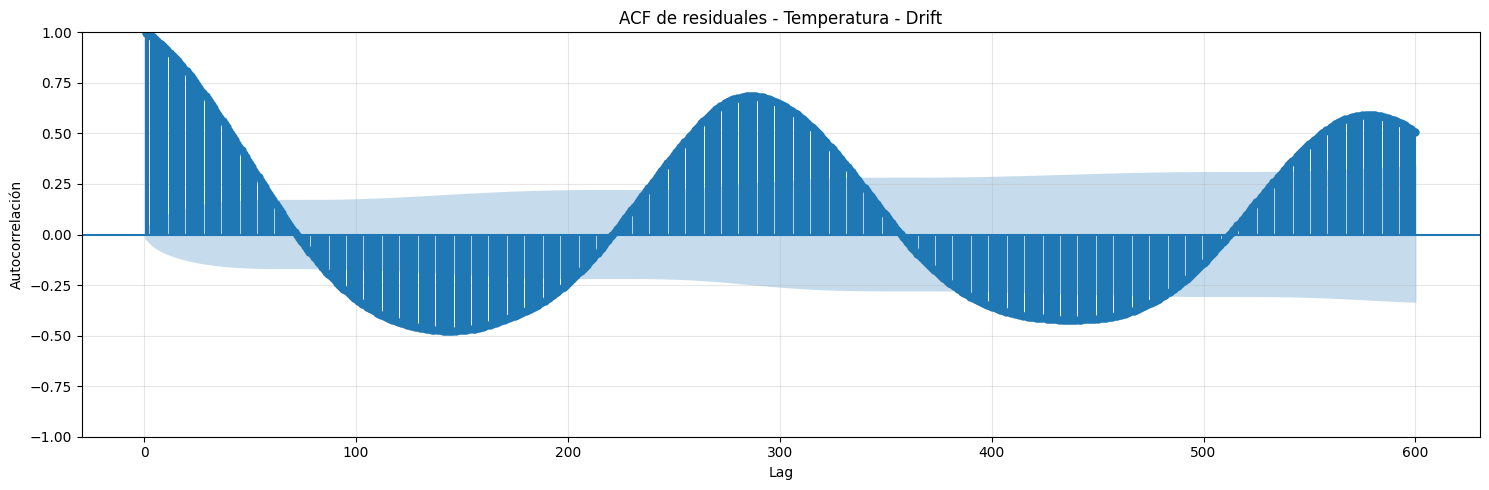

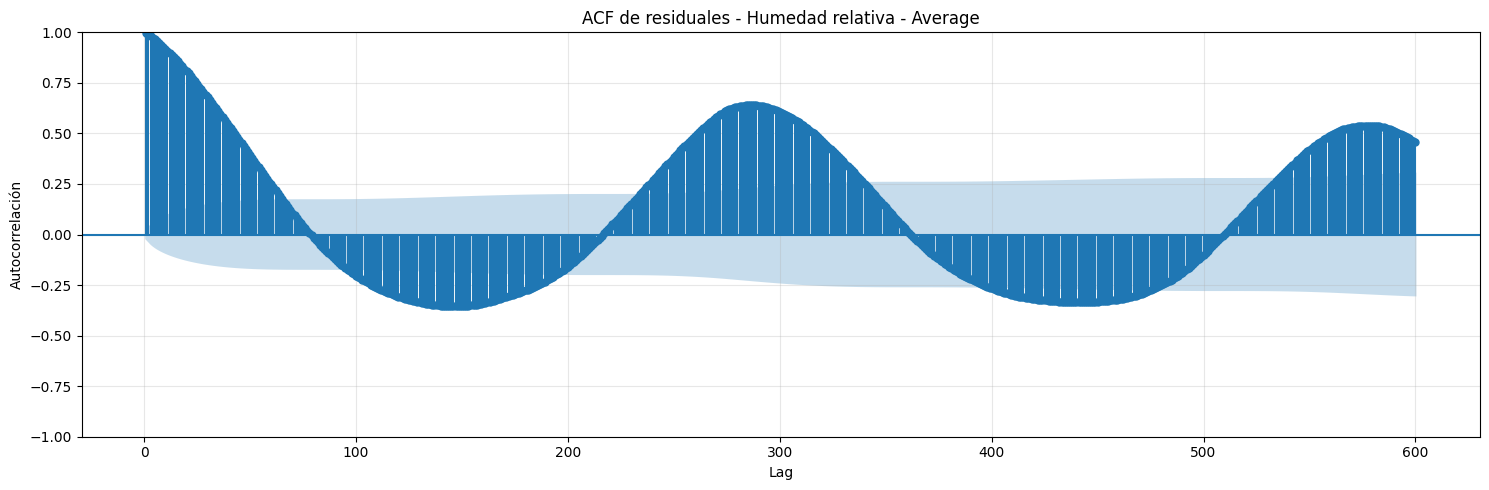

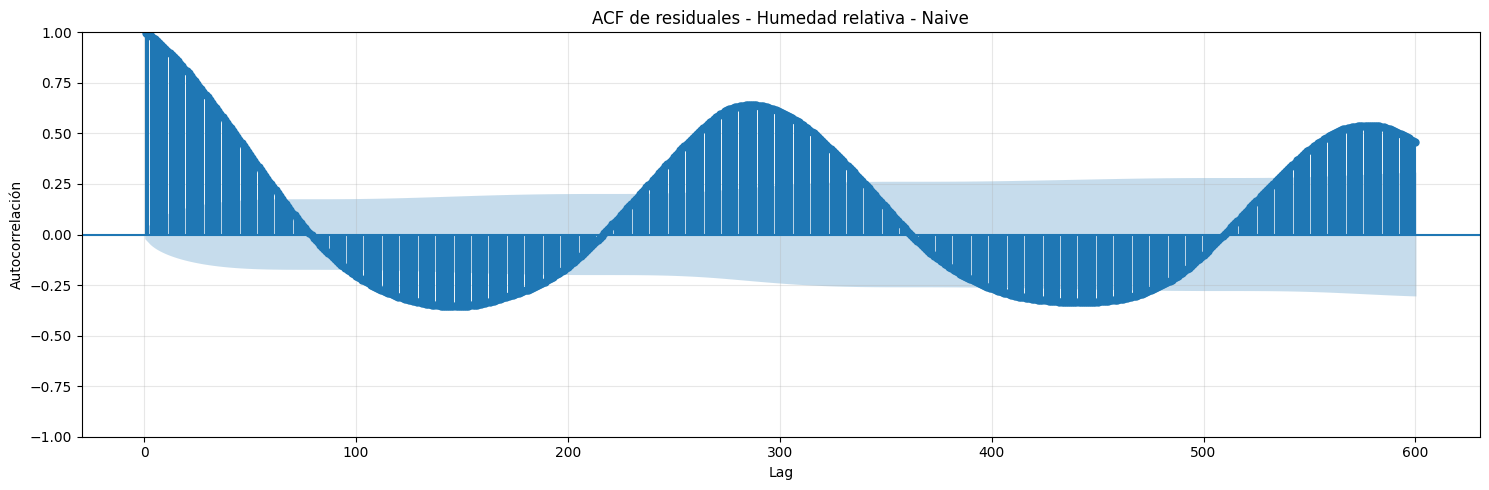

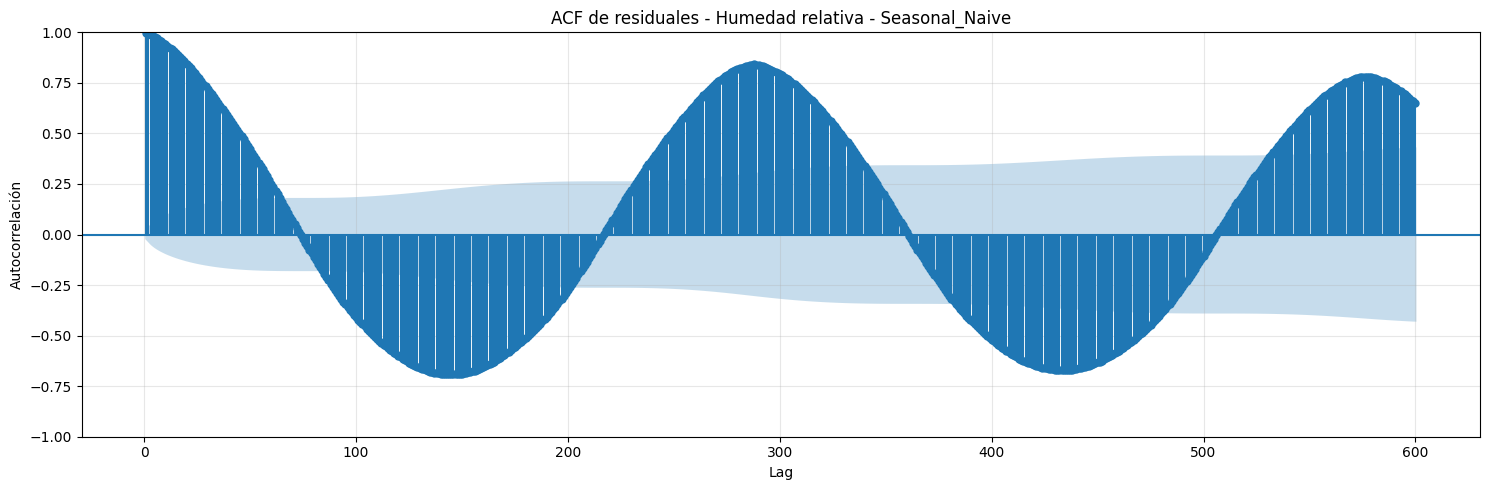

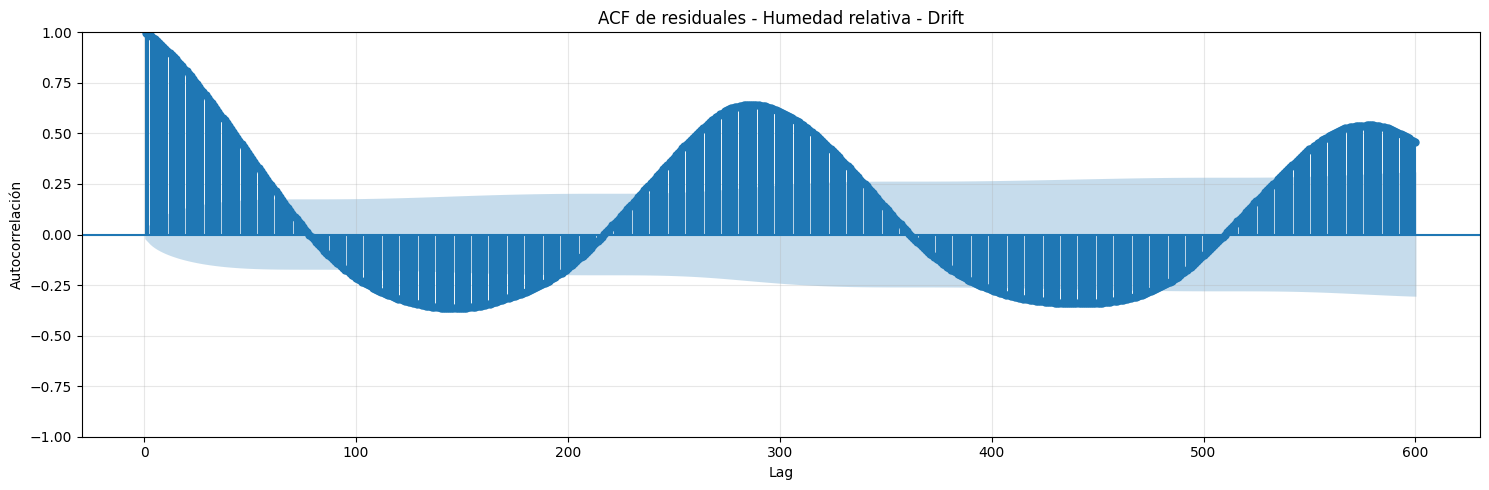

In [ ]:
# ================================================================
# 6. ACF DE LOS RESIDUALES
# ================================================================

def acf_residuales(
    residuales,
    variable,
    lags=600
):

    for modelo in residuales.columns:

        fig, ax = plt.subplots(
            figsize=(15, 5)
        )

        plot_acf(
            residuales[modelo].dropna(),
            lags=lags,
            zero=False,
            ax=ax
        )

        ax.set_title(
            f"ACF de residuales - {variable} - {modelo}"
        )

        ax.set_xlabel("Lag")
        ax.set_ylabel("Autocorrelación")

        ax.grid(alpha=0.3)

        plt.tight_layout()
        plt.show()


# Temperatura

acf_residuales(
    res_temp,
    "Temperatura",
    lags=600
)


# Humedad relativa

acf_residuales(
    res_hum,
    "Humedad relativa",
    lags=600
)

In [ ]:
# ================================================================
# 7. PRUEBA DE LJUNG-BOX
# ================================================================

def prueba_ljung_box(
    residuales,
    variable
):

    resultados = []

    # Lags representativos
    lags_evaluar = [
        12,
        72,
        144,
        288
    ]

    for modelo in residuales.columns:

        serie = (
            residuales[modelo]
            .dropna()
        )

        prueba = acorr_ljungbox(
            serie,
            lags=lags_evaluar,
            return_df=True
        )

        for lag in lags_evaluar:

            resultados.append({

                "Variable":
                    variable,

                "Modelo":
                    modelo,

                "Lag":
                    lag,

                "Q Ljung-Box":
                    prueba.loc[
                        lag,
                        "lb_stat"
                    ],

                "p-value":
                    prueba.loc[
                        lag,
                        "lb_pvalue"
                    ]

            })

    return pd.DataFrame(
        resultados
    )


# ------------------------------------------------
# Temperatura
# ------------------------------------------------

lb_temp = prueba_ljung_box(
    res_temp,
    "Temperatura"
)


# ------------------------------------------------
# Humedad
# ------------------------------------------------

lb_hum = prueba_ljung_box(
    res_hum,
    "Humedad relativa"
)


# ------------------------------------------------
# Tabla general
# ------------------------------------------------

ljung_box = pd.concat(
    [
        lb_temp,
        lb_hum
    ],
    ignore_index=True
)

display(
    ljung_box.round(6)
)

,Variable,Modelo,Lag,Q Ljung-Box,p-value
0,Temperatura,Average,12,81526.149488,0.0
1,Temperatura,Average,72,210840.041488,0.0
2,Temperatura,Average,144,282129.107098,0.0
3,Temperatura,Average,288,471903.508135,0.0
4,Temperatura,Naive,12,81526.149488,0.0
5,Temperatura,Naive,72,210840.041488,0.0
6,Temperatura,Naive,144,282129.107098,0.0
7,Temperatura,Naive,288,471903.508135,0.0
8,Temperatura,Seasonal_Naive,12,84366.605488,0.0
9,Temperatura,Seasonal_Naive,72,240130.647266,0.0
